# 02. Причинная обработка и работа классификатора на потоке

Правила задачи: только причинная обработка (фильтры с состоянием, никаких `filtfilt` и
статистик по будущему), метки — никогда не признак, первый блок не классифицируется,
`fit_block(k)` получает метки только завершённого блока. Здесь мы:

1. проверяем сетку окон решения против итератора судьи (`io_utils.iter_scored_windows`);
2. проверяем причинность фильтров решения: поток чанками ≡ обработке целиком, а изменение
   будущих отсчётов не меняет прошлые выходы (в отличие от `sosfiltfilt`);
3. смотрим частотные характеристики фильтров ЭЭГ и NIRS;
4. прогоняем боевой `OnlineClassifier` (артефакты сдачи) по одной сессии так же, как каркас
   судьи, и смотрим вероятности ЭЭГ, NIRS и гибрида во времени, работу охраны от артефактов
   и тайминги;
5. проверяем деградацию до ЭЭГ-only без NIRS.

In [1]:
import os, sys, json, time, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "assets":
    ROOT = ROOT.parent
SOL = ROOT / "solution"
sys.path.insert(0, str(SOL))
# каталог с сессиями *.mat (распакованный data.zip организаторов: data/Data/*.mat);
# переопределяется переменной окружения HORMIGAS_DATA
DATA = Path(os.environ.get("HORMIGAS_DATA", ROOT / "data" / "Data"))
SESSIONS = sorted(p for p in DATA.glob("*.mat") if p.name.lower() != "montage.mat")
MONTAGE = next((p for p in (DATA / "Montage.mat", DATA.parent / "Montage.mat") if p.exists()), None)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
CLASS_NAMES = {1: "покой", 2: "левая", 3: "правая"}
print("сессий:", len(SESSIONS), "| Montage.mat:", MONTAGE is not None)

сессий: 56 | Montage.mat: True


## 1. Сетка окон

In [2]:
import io_utils as iu
from session_io import window_ends

S = SESSIONS[0]
sess = iu.load_session(S)                                   # формат каркаса судьи
judge = np.array([(e, y) for _, e, y in iu.iter_scored_windows(sess["states"], sess["blocks"], sess["fs_eeg"])])
ends, y, blk = window_ends(sess["states"], sess["blocks"], sess["fs_eeg"])
ours = np.c_[ends, y][blk != 1]
print("окон у судьи:", len(judge), "| у решения:", len(ours), "| совпадают:", np.array_equal(judge, ours))
print("шаг сетки внутри сегмента, отсчётов:", np.diff(judge[:, 0]).min(), "(= round(250/4) = 62, не 62.5)")

окон у судьи: 1550 | у решения: 1550 | совпадают: True
шаг сетки внутри сегмента, отсчётов: 62 (= round(250/4) = 62, не 62.5)


## 2. Причинность фильтров

`CausalFilterBank` — боевой фильтр-банк ЭЭГ (`solution/eeg_model.py`): HP 1 Гц + режектор 50 Гц,
затем 7 полос Баттерворта, `sosfilt` с сохраняемым состоянием `zi`.

In [3]:
from eeg_model import CausalFilterBank
from scipy import signal as ss

x = sess["eeg"][:250 * 60].astype(np.float64)                  # 60 с
whole = CausalFilterBank(250.0, x.shape[1], bands=[(4, 8), (8, 10), (10, 13), (13, 18), (18, 24), (24, 30), (8, 30)]).process(x)

rng = np.random.default_rng(0)
fb = CausalFilterBank(250.0, x.shape[1], bands=[(4, 8), (8, 10), (10, 13), (13, 18), (18, 24), (24, 30), (8, 30)])
cuts = np.r_[0, np.sort(rng.choice(np.arange(1, len(x)), 300, replace=False)), len(x)]
stream = np.concatenate([fb.process(x[a:b]) for a, b in zip(cuts[:-1], cuts[1:])])
print("поток случайными чанками vs целиком: max |Δ| =", float(np.abs(stream - whole).max()))

t0 = 250 * 30                                                    # меняем «будущее» после 30 с
x2 = x.copy(); x2[t0:] += rng.standard_normal(x2[t0:].shape) * 50
fut = CausalFilterBank(250.0, x.shape[1], bands=[(4, 8), (8, 10), (10, 13), (13, 18), (18, 24), (24, 30), (8, 30)]).process(x2)
print("решение: изменение будущего меняет прошлые выходы? max |Δ| до t0 =", float(np.abs(fut[:t0] - whole[:t0]).max()))

sos = ss.butter(4, [8, 30], "bandpass", fs=250, output="sos")
ff1, ff2 = ss.sosfiltfilt(sos, x, axis=0), ss.sosfiltfilt(sos, x2, axis=0)
print("для сравнения sosfiltfilt (запрещён): max |Δ| до t0 =", float(np.abs(ff2[:t0] - ff1[:t0]).max()))

поток случайными чанками vs целиком: max |Δ| = 0.0
решение: изменение будущего меняет прошлые выходы? max |Δ| до t0 = 0.0
для сравнения sosfiltfilt (запрещён): max |Δ| до t0 = 28.7237804706092


## 3. Частотные характеристики

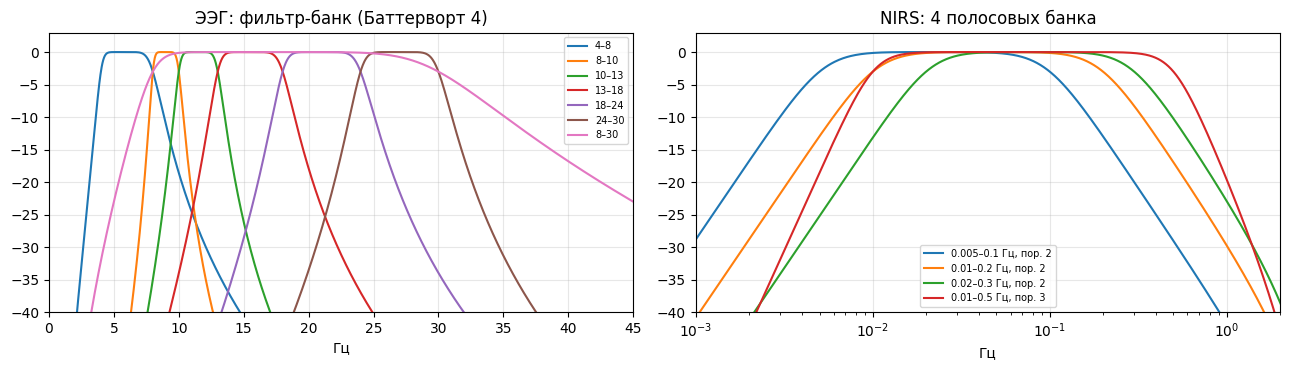

частота NIRS в этой сессии: 12.5


In [4]:
from eeg_model import CausalFilterBank
from nirs_model import BANKS, bandpass_sos

fb = CausalFilterBank(250.0, 21, bands=[(4, 8), (8, 10), (10, 13), (13, 18), (18, 24), (24, 30), (8, 30)])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for sos, (lo, hi) in zip(fb.band_sos, [(4, 8), (8, 10), (10, 13), (13, 18), (18, 24), (24, 30), (8, 30)]):
    w, h = ss.sosfreqz(sos, worN=4096, fs=250)
    ax[0].plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f"{lo}–{hi}")
ax[0].set_xlim(0, 45); ax[0].set_ylim(-40, 3); ax[0].set_title("ЭЭГ: фильтр-банк (Баттерворт 4)"); ax[0].set_xlabel("Гц"); ax[0].legend(fontsize=7)
fsn = 7.8125
for name, (lo, hi, order) in BANKS.items():
    w, h = ss.sosfreqz(bandpass_sos(fsn, lo, hi, order), worN=2 ** 15, fs=fsn)
    ax[1].semilogx(w[1:], 20 * np.log10(np.abs(h[1:]) + 1e-12), label=f"{lo}–{hi} Гц, пор. {order}")
ax[1].set_xlim(1e-3, 2); ax[1].set_ylim(-40, 3); ax[1].set_title("NIRS: 4 полосовых банка"); ax[1].set_xlabel("Гц"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("частота NIRS в этой сессии:", sess["fs_nirs"])

## 4. Боевой классификатор на потоке

Эмулируем каркас судьи (`solution/run.py`): отдаём ЭЭГ чанками до каждой точки сетки (+ NIRS с
`Frame` в этом интервале), в конце каждого блока вызываем `fit_block` в официальном формате
`{"states", "eeg_indices", "block"}` (только отсчёты завершённого блока). Для визуализации после
каждого `push` читаем внутренние вероятности `clf.last_proba` (судьёй не используются).

Артефакты сдачи обучены на всех 56 сессиях, поэтому качество на train здесь завышено — это
демонстрация механики; честные цифры — в `03_online_simulation.ipynb`.

In [5]:
from classifier import OnlineClassifier

def stream_session(sess, use_nirs=True, record=True):
    meta = iu.session_meta(sess)
    if not use_nirs:
        meta = dict(meta, has_nirs=False)
    clf = OnlineClassifier(meta); clf.load(SOL / "artifacts")
    st, bl, fs, n = sess["states"], sess["blocks"], sess["fs_eeg"], len(sess["states"])
    block_end = {int(b): int(np.flatnonzero(bl == b)[-1]) + 1 for b in np.unique(bl) if b >= 1}
    grid = np.arange(250, n + 1, 62)
    events = sorted([(e, 0) for e in grid] + [(e, 1) for e in block_end.values()])
    cur, rec, tp, tf = 0, [], [], []
    for e, kind in events:
        if e > cur:
            nirs = iu.nirs_slice_for_eeg_range(sess, cur, e) if (use_nirs and sess["has_nirs"]) else (None, None)
            clf.push(sess["eeg"][cur:e], nirs); cur = e
        if kind == 1:
            b = [k for k, v in block_end.items() if v == e][0]
            mask = (bl == b) & (st > 0)
            t0 = time.perf_counter(); clf.fit_block(b, {"states": st[mask], "eeg_indices": np.flatnonzero(mask), "block": b})
            tf.append(time.perf_counter() - t0)
            continue
        t0 = time.perf_counter(); out = clf.predict(); tp.append(time.perf_counter() - t0)
        if record:
            lp = clf.last_proba
            rec.append(dict(end=e, true=int(st[e - 1]), block=int(bl[e - 1]), y=out["y"], y_eeg=out.get("y_eeg"),
                            y_nirs=out.get("y_nirs"), flagged=clf.eeg.is_flagged(e),
                            z=(clf.eeg.zs[-1] if len(clf.eeg.zs) else 0.0),
                            **{f"pe{k}": (lp["eeg"][k - 1] if lp["eeg"] is not None else np.nan) for k in (1, 2, 3)},
                            **{f"pn{k}": (lp["nirs"][k - 1] if lp["nirs"] is not None else np.nan) for k in (1, 2, 3)}))
    return clf, pd.DataFrame(rec), np.array(tp), np.array(tf)

t0 = time.time()
clf, rec, tp, tf = stream_session(sess)
print(f"сессия {S.stem}: {len(rec)} точек сетки, {len(tf)} fit_block, {time.time() - t0:.0f} с")
print(f"predict: mean {tp.mean() * 1e6:.1f} мкс, max {tp.max() * 1e3:.3f} мс (бюджет 200 мс)")
print(f"fit_block: mean {tf.mean():.2f} с, max {tf.max():.2f} с (бюджет 1.5 с)")

сессия 2025.12.01.16.04.01_N01: 2409 точек сетки, 7 fit_block, 42 с
predict: mean 2.3 мкс, max 0.018 мс (бюджет 200 мс)
fit_block: mean 0.65 с, max 0.80 с (бюджет 1.5 с)


In [6]:
# оцениваемые окна = те же, что у судьи (однородные, блоки 2–7)
sc = rec.set_index("end").loc[judge[:, 0]]
assert (sc.true.values == judge[:, 1]).all()
from score import confusion_from_preds, metrics_block
for col, title in (("y", "гибрид"), ("y_eeg", "ЭЭГ"), ("y_nirs", "NIRS")):
    m = metrics_block(confusion_from_preds(sc.true.values, sc[col].values.astype(int)))
    print(f"{title:7s} min-F1 = {m['min_f1']:.3f}   macro-recall = {m['macro_recall']:.3f}")

гибрид  min-F1 = 0.787   macro-recall = 0.824
ЭЭГ     min-F1 = 0.717   macro-recall = 0.786
NIRS    min-F1 = 0.555   macro-recall = 0.618


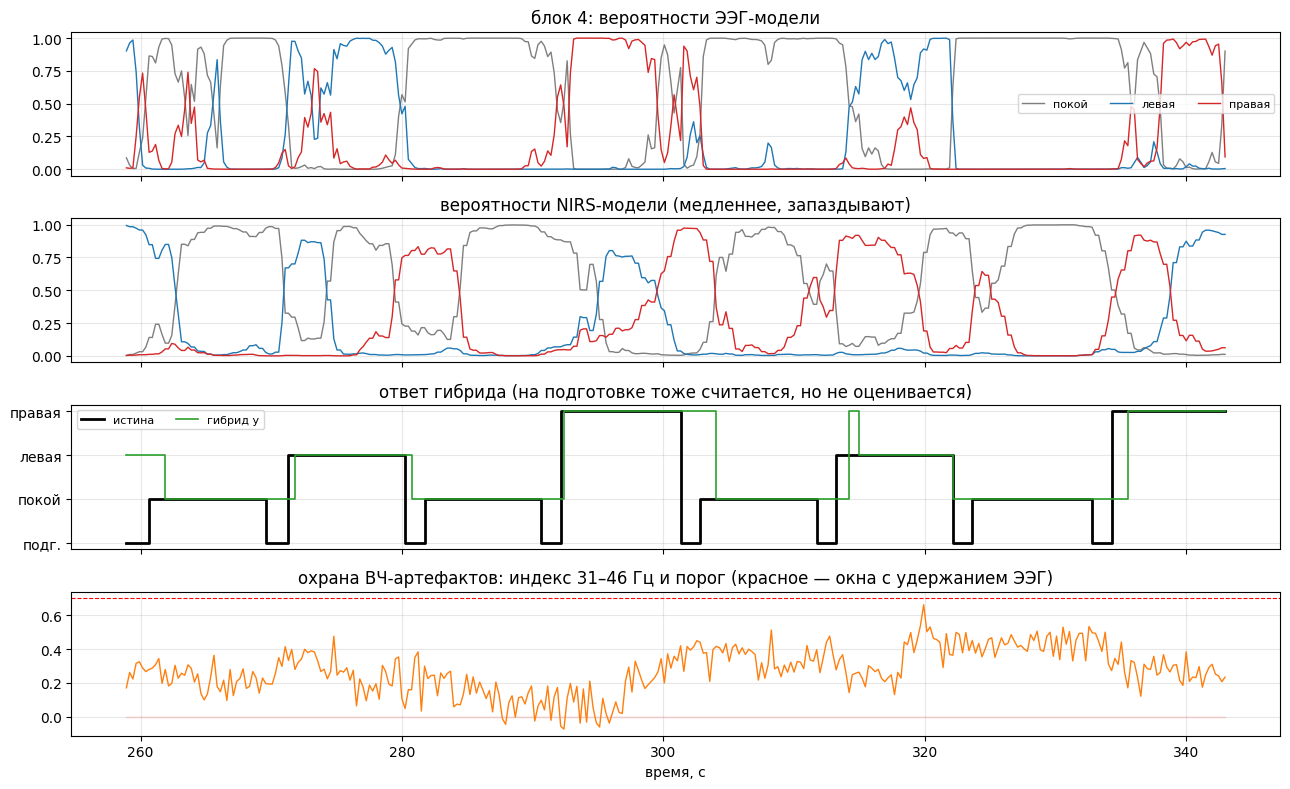

доля окон под охраной в сессии: 0.038


In [7]:
b = 4
d = rec[rec.block == b]
tt = d.end.values / 250.0
fig, ax = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for k, c in zip((1, 2, 3), ("C7", "C0", "C3")):
    ax[0].plot(tt, d[f"pe{k}"], c, lw=1, label=CLASS_NAMES[k]); ax[1].plot(tt, d[f"pn{k}"], c, lw=1)
ax[0].set_title(f"блок {b}: вероятности ЭЭГ-модели"); ax[0].legend(ncol=3, fontsize=8)
ax[1].set_title("вероятности NIRS-модели (медленнее, запаздывают)")
ax[2].step(tt, d.true, "k", where="post", lw=2, label="истина")
ax[2].step(tt, d.y, "C2", where="post", lw=1.2, label="гибрид y")
ax[2].set_yticks([0, 1, 2, 3], ["подг.", "покой", "левая", "правая"]); ax[2].legend(ncol=2, fontsize=8)
ax[2].set_title("ответ гибрида (на подготовке тоже считается, но не оценивается)")
ax[3].plot(tt, d.z, "C1", lw=1)
ax[3].axhline(clf.eeg.thr, color="r", ls="--", lw=0.8)
ax[3].fill_between(tt, 0, d.flagged.astype(float) * 2, color="r", alpha=0.15, step="post")
ax[3].set_title("охрана ВЧ-артефактов: индекс 31–46 Гц и порог (красное — окна с удержанием ЭЭГ)")
ax[3].set_xlabel("время, с")
plt.tight_layout(); plt.show()
print("доля окон под охраной в сессии:", round(float(rec.flagged.mean()), 3))

## 5. Деградация без NIRS

При `has_nirs=False` решение использует только ЭЭГ (мета-модель `models.eeg`); `y` должен
совпасть с `y_eeg` и не зависеть от наличия NIRS-модели.

In [8]:
clf2, rec2, tp2, tf2 = stream_session(sess, use_nirs=False)
print("NIRS-модель создана:", clf2.nirs is not None, "| y_nirs без NIRS:", rec2.y_nirs.unique()[:3])
print("y без NIRS совпадает с ЭЭГ-ответом y_eeg прогона с NIRS на всех точках сетки:", bool((rec2.y.values == rec.y_eeg.values).all()))
print("y без NIRS отличается от гибрида с NIRS в доле точек:", round(float((rec2.y.values != rec.y.values).mean()), 3))
sc2 = rec2.set_index("end").loc[judge[:, 0]]
m2 = metrics_block(confusion_from_preds(sc2.true.values, sc2.y.values.astype(int)))
print(f"ЭЭГ-only: min-F1 = {m2['min_f1']:.3f}, macro-recall = {m2['macro_recall']:.3f}")

NIRS-модель создана: False | y_nirs без NIRS: [None]
y без NIRS совпадает с ЭЭГ-ответом y_eeg прогона с NIRS на всех точках сетки: False
y без NIRS отличается от гибрида с NIRS в доле точек: 0.157
ЭЭГ-only: min-F1 = 0.717, macro-recall = 0.786


## Итоги

* Сетка окон решения совпадает с судейской (шаг 62 отсчёта).
* Фильтры решения причинные: поток ≡ обработка целиком, будущее не влияет на прошлое.
* Вся работа идёт в `push` на каждой точке сетки (асинхронный режим), `predict` только отдаёт
  последнее решение — микросекунды; `fit_block` укладывается в 1.5 с.
* Без NIRS решение работает как ЭЭГ-only.